In [16]:
import os

os.environ["KAGGLE_API_TOKEN"] = "KGAT_9a59832e78dda15b7a09bbdd1a265554"

print("Kaggle API token configured successfully!")

Kaggle API token configured successfully!


In [17]:
!pip install -q kaggle

In [18]:
!kaggle competitions list

ref                                                                           deadline             category         reward  teamCount  userHasEntered  
----------------------------------------------------------------------------  -------------------  --------  -------------  ---------  --------------  
https://www.kaggle.com/competitions/passenger-screening-algorithm-challenge   2017-12-15 23:59:00  Featured  1,500,000 Usd        518           False  
https://www.kaggle.com/competitions/zillow-prize-1                            2018-01-10 15:59:00  Featured  1,200,000 Usd       3770           False  
https://www.kaggle.com/competitions/data-science-bowl-2017                    2017-04-12 23:59:00  Featured  1,000,000 Usd       1972           False  
https://www.kaggle.com/competitions/vesuvius-challenge-ink-detection          2023-06-14 23:59:00  Featured  1,000,000 Usd       1249           False  
https://www.kaggle.com/competitions/arc-prize-2026-arc-agi-3                  2026-11-02

In [19]:
!kaggle competitions download -c dogs-vs-cats


dogs-vs-cats.zip: Skipping, found more recently modified local copy (use --force to force download)


In [20]:
!mkdir -p /content/dogs_vs_cats

!unzip -q dogs-vs-cats.zip -d /content/dogs_vs_cats

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [21]:
!mkdir -p /content/dogs_vs_cats/train_images

!unzip -q /content/dogs_vs_cats/train.zip \
    -d /content/dogs_vs_cats/train_images

print("Training images extracted successfully!")

Training images extracted successfully!


In [22]:
import os

train_path = "/content/dogs_vs_cats/train_images/train"

print("Total training images:",
      len(os.listdir(train_path)))

print("\nFirst 10 images:")
print(os.listdir(train_path)[:10])

Total training images: 25000

First 10 images:
['cat.10676.jpg', 'cat.11001.jpg', 'cat.9258.jpg', 'cat.2279.jpg', 'dog.1978.jpg', 'dog.638.jpg', 'dog.5617.jpg', 'dog.5826.jpg', 'cat.11110.jpg', 'cat.12335.jpg']


In [23]:
import glob

train_path = "/content/dogs_vs_cats/train_images/train"

cat_images = glob.glob(train_path + "/cat.*.jpg")
dog_images = glob.glob(train_path + "/dog.*.jpg")

print("Total Cat images:", len(cat_images))
print("Total Dog images:", len(dog_images))

Total Cat images: 12500
Total Dog images: 12500


In [24]:
import random

random.seed(42)

cat_images = random.sample(cat_images, 1000)
dog_images = random.sample(dog_images, 1000)

print("Selected Cat images:", len(cat_images))
print("Selected Dog images:", len(dog_images))
print("Total selected images:", len(cat_images) + len(dog_images))

Selected Cat images: 1000
Selected Dog images: 1000
Total selected images: 2000


In [25]:
import numpy as np
from PIL import Image
from skimage.feature import hog

X = []
y = []

IMG_SIZE = 64

# -------------------------
# Cat images
# Cat = 0
# -------------------------
for image_path in cat_images:

    img = Image.open(image_path).convert('L')
    img = img.resize((IMG_SIZE, IMG_SIZE))

    img_array = np.array(img)

    features = hog(
        img_array,
        orientations=9,
        pixels_per_cell=(8, 8),
        cells_per_block=(2, 2),
        block_norm='L2-Hys'
    )

    X.append(features)
    y.append(0)


# -------------------------
# Dog images
# Dog = 1
# -------------------------
for image_path in dog_images:

    img = Image.open(image_path).convert('L')
    img = img.resize((IMG_SIZE, IMG_SIZE))

    img_array = np.array(img)

    features = hog(
        img_array,
        orientations=9,
        pixels_per_cell=(8, 8),
        cells_per_block=(2, 2),
        block_norm='L2-Hys'
    )

    X.append(features)
    y.append(1)


# Convert to NumPy arrays
X = np.array(X)
y = np.array(y)

print("Feature extraction completed successfully!")
print("Feature shape:", X.shape)
print("Label shape:", y.shape)

Feature extraction completed successfully!
Feature shape: (2000, 1764)
Label shape: (2000,)


In [26]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

Training data: (1600, 1764)
Testing data: (400, 1764)
Training labels: (1600,)
Testing labels: (400,)


In [27]:
from sklearn.svm import SVC

model = SVC(
    kernel='rbf',
    C=10,
    gamma='scale'
)

model.fit(X_train, y_train)

print("SVM model training completed successfully!")

SVM model training completed successfully!


In [28]:
y_pred = model.predict(X_test)

print("Prediction completed successfully!")

print("\nFirst 20 predictions:")
print(y_pred[:20])

Prediction completed successfully!

First 20 predictions:
[0 1 1 0 1 1 1 0 0 1 0 1 1 1 0 0 0 1 0 1]


In [29]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("SVM Model Accuracy:", accuracy)
print("SVM Model Accuracy (%):", accuracy * 100)

SVM Model Accuracy: 0.7225
SVM Model Accuracy (%): 72.25


In [30]:
from sklearn.metrics import classification_report

print("Classification Report:\n")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Cat", "Dog"]
    )
)

Classification Report:

              precision    recall  f1-score   support

         Cat       0.72      0.73      0.72       200
         Dog       0.73      0.71      0.72       200

    accuracy                           0.72       400
   macro avg       0.72      0.72      0.72       400
weighted avg       0.72      0.72      0.72       400



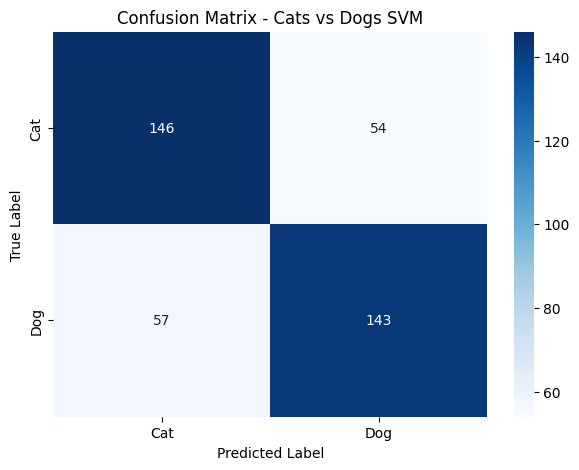

In [31]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Cat', 'Dog'],
    yticklabels=['Cat', 'Dog']
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix - Cats vs Dogs SVM")

plt.show()

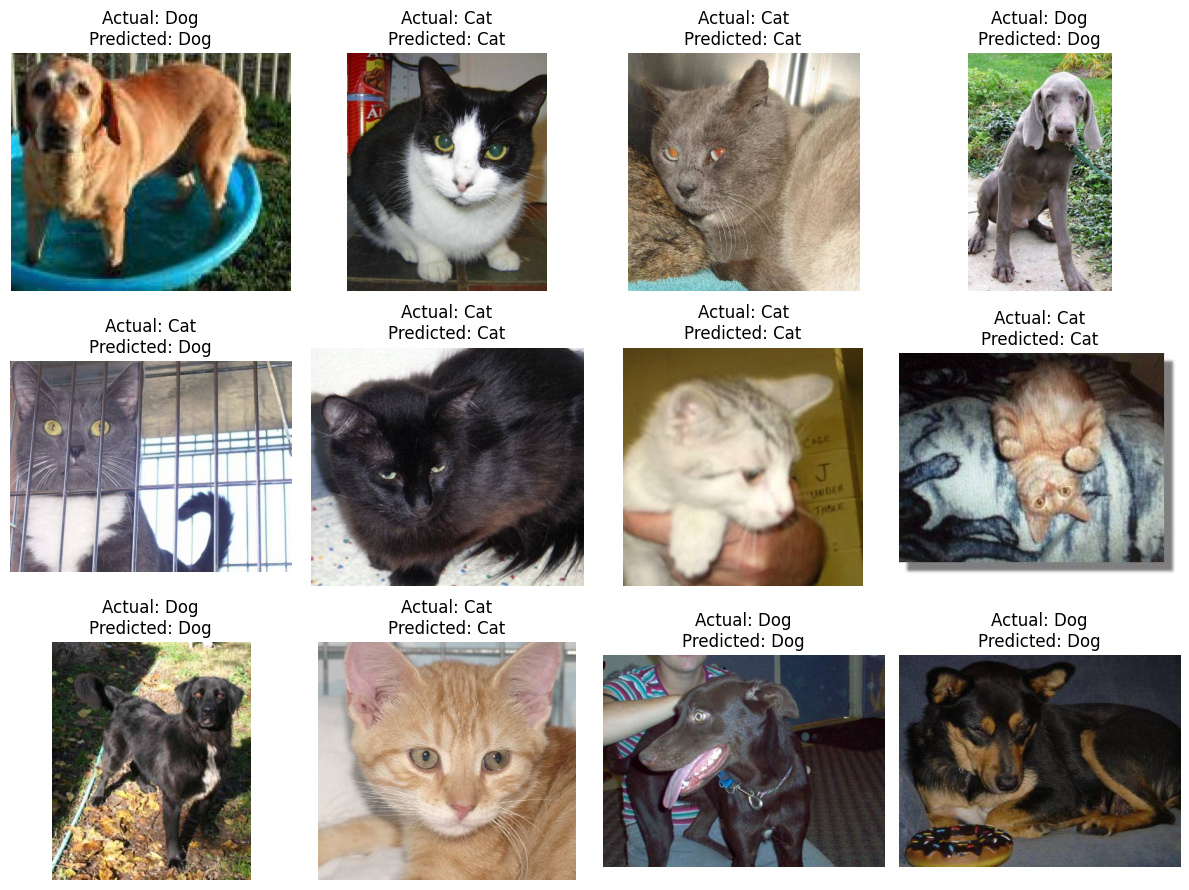

In [32]:
import matplotlib.pyplot as plt
import random

# Create a list of test image paths
all_test_paths = cat_images + dog_images

# Select 12 random images
random.seed(42)
sample_paths = random.sample(all_test_paths, 12)

plt.figure(figsize=(12, 9))

for i, image_path in enumerate(sample_paths):

    # Load image
    img = Image.open(image_path)

    # Extract HOG feature
    gray_img = img.convert('L')
    gray_img = gray_img.resize((64, 64))
    img_array = np.array(gray_img)

    features = hog(
        img_array,
        orientations=9,
        pixels_per_cell=(8, 8),
        cells_per_block=(2, 2),
        block_norm='L2-Hys'
    )

    # Predict
    prediction = model.predict([features])[0]

    # Actual label
    actual = 0 if "cat." in image_path else 1

    predicted_label = "Cat" if prediction == 0 else "Dog"
    actual_label = "Cat" if actual == 0 else "Dog"

    # Display
    plt.subplot(3, 4, i + 1)
    plt.imshow(img)
    plt.axis('off')

    plt.title(
        f"Actual: {actual_label}\nPredicted: {predicted_label}"
    )

plt.tight_layout()
plt.show()